In [1]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#load dataset
mat = pd.read_csv("matches.csv")

print("dataset loaded successfully")
print("Matchs:", mat.shape)

dataset loaded successfully
Matchs: (39, 23)


In [3]:
# understanding match dataset
mat.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,...,match_winner,wb_runs,wb_wickets,balls_left,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,super_over_match
0,1,"March 28, 2026","M. Chinnaswamy Stadium, Bangalore",RCB,SRH,League,RCB,Bowl,201.0,9.0,...,RCB,NaN,6.0,26.0,Jacob Duffy,Ishan Kishan,80.0,Jacob Duffy,3--22,No
1,2,"March 29, 2026","Wankhede Stadium, Mumbai",MI,KKR,League,MI,Bowl,220.0,4.0,...,MI,NaN,6.0,5.0,Shardul Thakur,Ryan Rickelton,81.0,Shardul Thakur,3--39,No
2,3,"March 30, 2026","Barsapara Stadium, Guwahati",RR,CSK,League,RR,Bowl,127.0,10.0,...,RR,NaN,8.0,47.0,Nandre Burger,Vaibhav Sooryavanshi,52.0,Jofra Archer,2--19,No
3,4,"March 31, 2026","New PCA Cricket Stadium, Mullanpur",PBKS,GT,League,PBKS,Bowl,162.0,6.0,...,PBKS,NaN,3.0,5.0,Cooper Connolly,Cooper Connolly,72.0,Prasidh Krishna,3--29,No
4,5,"April 01, 2026","Ekana Cricket Stadium, Lucknow",LSG,DC,League,DC,Bowl,141.0,10.0,...,DC,NaN,6.0,17.0,Sameer Rizvi,Sameer Rizvi,70.0,Lungi Ngidi,3--27,No


In [4]:
mat.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   match_id             39 non-null     int64  
 1   date                 39 non-null     str    
 2   venue                39 non-null     str    
 3   team1                39 non-null     str    
 4   team2                39 non-null     str    
 5   stage                39 non-null     str    
 6   toss_winner          39 non-null     str    
 7   toss_decision        39 non-null     str    
 8   first_ings_score     38 non-null     float64
 9   first_ings_wkts      38 non-null     float64
 10  second_ings_score    38 non-null     float64
 11  second_ings_wkts     38 non-null     float64
 12  match_result         39 non-null     str    
 13  match_winner         38 non-null     str    
 14  wb_runs              15 non-null     float64
 15  wb_wickets           22 non-null     float64
 16  bal

In [5]:
mat.describe()

,match_id,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,wb_runs,wb_wickets,balls_left,highscore
count,39.000000,38.000000,38.000000,38.000000,38.000000,15.000000,22.000000,38.000000,38.000000
mean,20.000000,190.526316,6.289474,175.500000,6.052632,41.666667,5.772727,10.684211,79.447368
std,11.401754,39.394565,2.470451,39.747684,2.670635,30.658643,1.477830,15.773918,24.521031
min,1.000000,75.000000,2.000000,77.000000,1.000000,1.000000,3.000000,0.000000,34.000000
25%,10.500000,159.750000,4.250000,159.250000,4.000000,20.500000,5.000000,0.250000,60.750000
50%,20.000000,197.000000,6.000000,180.000000,5.000000,40.000000,6.000000,6.000000,77.500000
75%,29.500000,215.000000,8.000000,203.750000,8.000000,55.500000,6.000000,12.000000,91.750000
max,39.000000,264.000000,10.000000,265.000000,10.000000,103.000000,9.000000,81.000000,152.000000


In [6]:
# cleaning match dataset
# fix the column
print(mat['best_bowling_figure'].unique()) # checking output we have to split it into 2 columns then convert to numeric 

<StringArray>
['3--22', '3--39', '2--19', '3--29', '3--27', '4--41', '2--38', '2--26',
  '2--9', '3--41',     nan, '3--17', '2--32', '2--30', '3--33', '4--18',
 '4--28', '2--47', '4--24', '3--21', '3--26', '3--14', '2--25', '4--32',
 '3--20', '4--17', '2--49', '2--46', '2--34', '3--25', '5--23', '4--12']
Length: 32, dtype: str


In [7]:
# split the column
mat[['bowling_wickets','bowling_runs']] = mat['best_bowling_figure'].str.split('--', expand=True) # 'expand=True' gives it as 2 separate columns
 
# convert these string column into numeric
mat['bowling_wickets'] = pd.to_numeric(mat['bowling_wickets'], errors='coerce')
mat['bowling_runs'] = pd.to_numeric(mat["bowling_runs"], errors='coerce')

# verify
print(mat['bowling_wickets'].dtype)
print(mat['bowling_runs'].dtype)
mat[['bowling_wickets','bowling_runs']].head()

float64
float64


,bowling_wickets,bowling_runs
0,3.0,22.0
1,3.0,39.0
2,2.0,19.0
3,3.0,29.0
4,3.0,27.0


In [8]:
# now drop column 'best_bowling_figure'
mat.drop('best_bowling_figure', axis=1, inplace=True)
# verify
mat.columns

Index(['match_id', 'date', 'venue', 'team1', 'team2', 'stage', 'toss_winner',
       'toss_decision', 'first_ings_score', 'first_ings_wkts',
       'second_ings_score', 'second_ings_wkts', 'match_result', 'match_winner',
       'wb_runs', 'wb_wickets', 'balls_left', 'player_of_the_match',
       'top_scorer', 'highscore', 'best_bowling', 'super_over_match',
       'bowling_wickets', 'bowling_runs'],
      dtype='str')

In [9]:
# dropping some unneccessary columns
Un_cols = ['wb_runs', 'wb_wickets', 
         'player_of_the_match',
       'top_scorer', 'highscore', 'best_bowling',]
         #'wb_runs', 'wb_wickets' either one of its alternatively null so we are removing this
        # remaining columns doesnt provide information for match winner prediction
mat.drop(Un_cols, axis=1, inplace=True)

# verify
mat.columns

Index(['match_id', 'date', 'venue', 'team1', 'team2', 'stage', 'toss_winner',
       'toss_decision', 'first_ings_score', 'first_ings_wkts',
       'second_ings_score', 'second_ings_wkts', 'match_result', 'match_winner',
       'balls_left', 'super_over_match', 'bowling_wickets', 'bowling_runs'],
      dtype='str')

In [10]:
#check for missing values
print('before', mat.shape)
mat.isnull().sum()

before (39, 18)


match_id             0
date                 0
venue                0
team1                0
team2                0
stage                0
toss_winner          0
toss_decision        0
first_ings_score     1
first_ings_wkts      1
second_ings_score    1
second_ings_wkts     1
match_result         0
match_winner         1
balls_left           1
super_over_match     0
bowling_wickets      1
bowling_runs         1
dtype: int64

In [11]:
# removing null values
mat.dropna(inplace=True)
print('after', mat.shape)

after (38, 18)


In [12]:
# checking duplicate values
mat.duplicated().sum() # no duplictaes

np.int64(0)

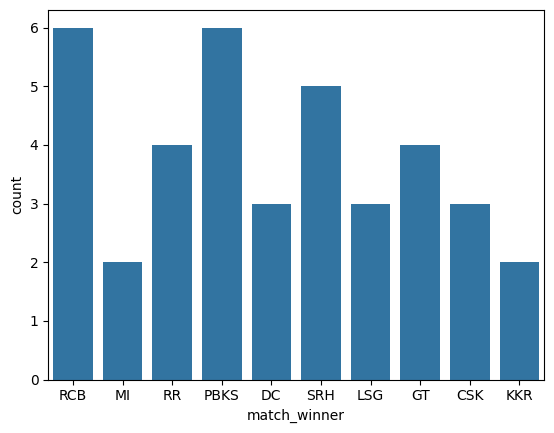

In [13]:
#EDA-Exploratory Data Analysis
sns.countplot(x='match_winner', data=mat)
plt.show()

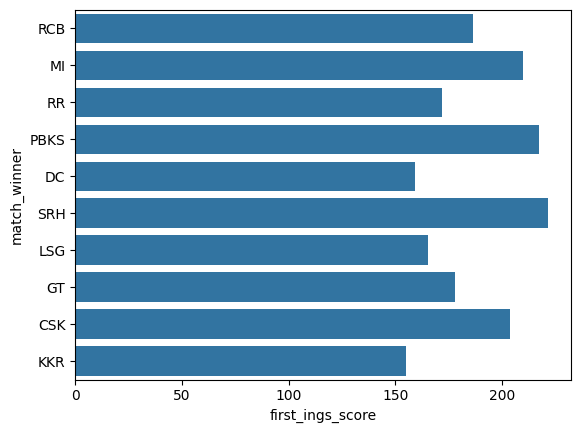

In [14]:
sns.barplot(x='first_ings_score', y='match_winner', data=mat, errorbar=None)
plt.show()

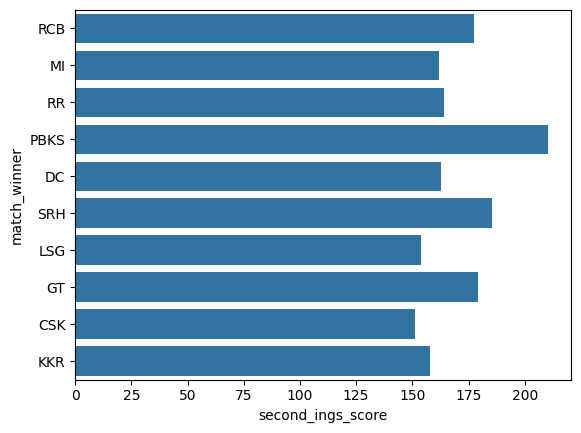

In [15]:
sns.barplot(x='second_ings_score', y='match_winner', data=mat, errorbar=None)
plt.show()

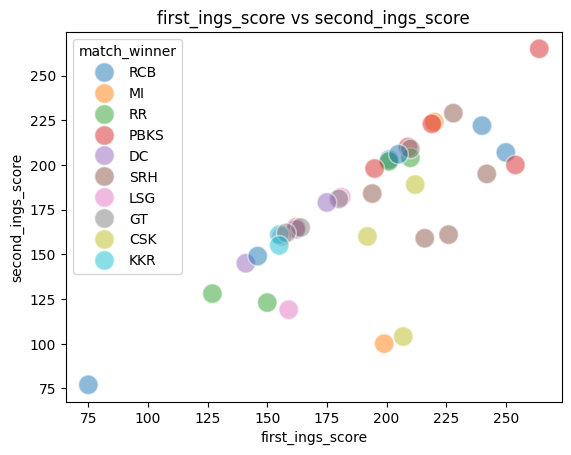

In [16]:
sns.scatterplot(x='first_ings_score', y='second_ings_score', data=mat, hue='match_winner', s=200, alpha=0.5) #hue - Each team gets a different color, and a legend appears:
plt.title('first_ings_score vs second_ings_score')
plt.show()

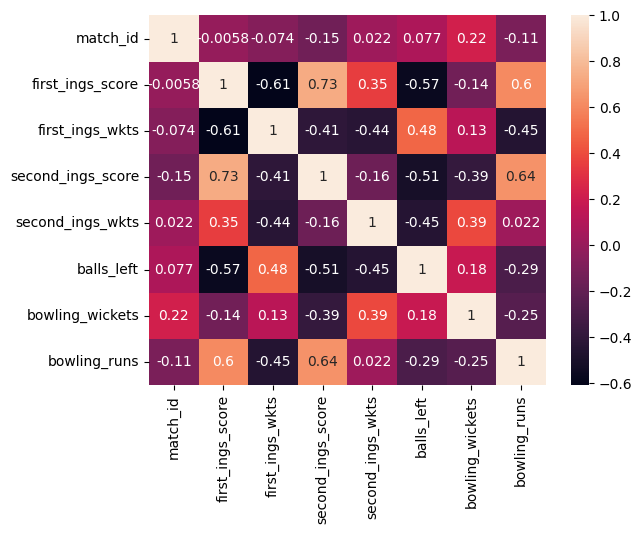

In [17]:
corr = mat.corr(numeric_only=True)
sns.heatmap(corr, annot=True)
plt.show()

In [18]:
mat.columns

Index(['match_id', 'date', 'venue', 'team1', 'team2', 'stage', 'toss_winner',
       'toss_decision', 'first_ings_score', 'first_ings_wkts',
       'second_ings_score', 'second_ings_wkts', 'match_result', 'match_winner',
       'balls_left', 'super_over_match', 'bowling_wickets', 'bowling_runs'],
      dtype='str')

In [19]:
col = ['match_id', 'date', 'venue', 'match_result', 'super_over_match', 'stage']
mat.drop(col, axis=1, inplace=True)
mat.columns

Index(['team1', 'team2', 'toss_winner', 'toss_decision', 'first_ings_score',
       'first_ings_wkts', 'second_ings_score', 'second_ings_wkts',
       'match_winner', 'balls_left', 'bowling_wickets', 'bowling_runs'],
      dtype='str')

In [20]:
mat.info()

<class 'pandas.DataFrame'>
Index: 38 entries, 0 to 38
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   team1              38 non-null     str    
 1   team2              38 non-null     str    
 2   toss_winner        38 non-null     str    
 3   toss_decision      38 non-null     str    
 4   first_ings_score   38 non-null     float64
 5   first_ings_wkts    38 non-null     float64
 6   second_ings_score  38 non-null     float64
 7   second_ings_wkts   38 non-null     float64
 8   match_winner       38 non-null     str    
 9   balls_left         38 non-null     float64
 10  bowling_wickets    38 non-null     float64
 11  bowling_runs       38 non-null     float64
dtypes: float64(7), str(5)
memory usage: 3.9 KB


In [21]:
mat.nunique() 

team1                10
team2                10
toss_winner          10
toss_decision         2
first_ings_score     34
first_ings_wkts       9
second_ings_score    35
second_ings_wkts     10
match_winner         10
balls_left           19
bowling_wickets       4
bowling_runs         26
dtype: int64

In [22]:
# label encoding
mat['toss_decision'] = mat['toss_decision'].map({'Bat' : 1, 'Bowl' : 0})
mat['match_winner'] = (mat['match_winner'] == mat['team1']).astype(int) 

# verify
print(mat['toss_decision'].unique())
print(mat['match_winner'].unique())
print(mat['match_winner'].value_counts())

[0 1]
[1 0]
match_winner
1    21
0    17
Name: count, dtype: int64


In [23]:
# one hot encoding
mat = pd.get_dummies(mat, columns = ['team1', 'team2', 'toss_winner'], drop_first=True, dtype=int)

# verify
print(mat.shape)
print(mat.info())

(38, 36)
<class 'pandas.DataFrame'>
Index: 38 entries, 0 to 38
Data columns (total 36 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   toss_decision      38 non-null     int64  
 1   first_ings_score   38 non-null     float64
 2   first_ings_wkts    38 non-null     float64
 3   second_ings_score  38 non-null     float64
 4   second_ings_wkts   38 non-null     float64
 5   match_winner       38 non-null     int64  
 6   balls_left         38 non-null     float64
 7   bowling_wickets    38 non-null     float64
 8   bowling_runs       38 non-null     float64
 9   team1_DC           38 non-null     int64  
 10  team1_GT           38 non-null     int64  
 11  team1_KKR          38 non-null     int64  
 12  team1_LSG          38 non-null     int64  
 13  team1_MI           38 non-null     int64  
 14  team1_PBKS         38 non-null     int64  
 15  team1_RCB          38 non-null     int64  
 16  team1_RR           38 non-null     

In [24]:
mat.describe()

,toss_decision,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,match_winner,balls_left,bowling_wickets,bowling_runs,team1_DC,...,team2_SRH,toss_winner_DC,toss_winner_GT,toss_winner_KKR,toss_winner_LSG,toss_winner_MI,toss_winner_PBKS,toss_winner_RCB,toss_winner_RR,toss_winner_SRH
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,...,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,0.105263,190.526316,6.289474,175.500000,6.052632,0.552632,10.684211,3.000000,27.868421,0.105263,...,0.105263,0.184211,0.078947,0.078947,0.131579,0.105263,0.105263,0.105263,0.131579,0.026316
std,0.311012,39.394565,2.470451,39.747684,2.670635,0.503897,15.773918,0.838274,9.695837,0.311012,...,0.311012,0.392859,0.273276,0.273276,0.342570,0.311012,0.311012,0.311012,0.342570,0.162221
min,0.000000,75.000000,2.000000,77.000000,1.000000,0.000000,0.000000,2.000000,9.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,159.750000,4.250000,159.250000,4.000000,0.000000,0.250000,2.000000,22.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,197.000000,6.000000,180.000000,5.000000,1.000000,6.000000,3.000000,26.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,215.000000,8.000000,203.750000,8.000000,1.000000,12.000000,4.000000,32.750000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,264.000000,10.000000,265.000000,10.000000,1.000000,81.000000,5.000000,49.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [25]:
#scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

s = ['first_ings_score', 'first_ings_wkts', 'second_ings_score', 'second_ings_wkts', 
     'balls_left', 'bowling_wickets', 'bowling_runs']

mat[s] = scaler.fit_transform(mat[s])

print(mat[s].describe().round(2))

       first_ings_score  first_ings_wkts  second_ings_score  second_ings_wkts  \
count             38.00            38.00              38.00             38.00   
mean               0.00            -0.00               0.00              0.00   
std                1.01             1.01               1.01              1.01   
min               -2.97            -1.76              -2.51             -1.92   
25%               -0.79            -0.84              -0.41             -0.78   
50%                0.17            -0.12               0.11             -0.40   
75%                0.63             0.70               0.72              0.74   
max                1.89             1.52               2.28              1.50   

       balls_left  bowling_wickets  bowling_runs  
count       38.00            38.00         38.00  
mean         0.00             0.00          0.00  
std          1.01             1.01          1.01  
min         -0.69            -1.21         -1.97  
25%         -0.

In [26]:
# train-test-split
from sklearn.model_selection import train_test_split

X = mat.drop('match_winner', axis=1) #features
Y = mat['match_winner']

X_train,X_test,Y_train,Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

# verify
print("X_train", X_train.shape)
print("X_test", X_test.shape)

X_train (30, 35)
X_test (8, 35)


In [27]:
# model training
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000) #default is 100
model.fit(X_train, Y_train)
LR_pred = model.predict(X_test)

# predicted and actual values
print("Predicted Values :", LR_pred)
print("Actual Values :", Y_test.values)


Predicted Values : [1 0 1 1 1 1 1 0]
Actual Values : [1 1 0 0 0 1 0 1]


In [28]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

# accuracy
print("Accuracy", accuracy_score(Y_test, LR_pred))
# confusion matrix
print("Confusion Matrix", confusion_matrix(Y_test, LR_pred))
# classification report ->f2score,recall...
print("classification report", classification_report(Y_test, LR_pred))

Accuracy 0.25
Confusion Matrix [[0 4]
 [2 2]]
classification report               precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.33      0.50      0.40         4

    accuracy                           0.25         8
   macro avg       0.17      0.25      0.20         8
weighted avg       0.17      0.25      0.20         8



In [29]:
# model 2
from sklearn.ensemble import RandomForestClassifier

RF = RandomForestClassifier(n_estimators=100,random_state=42) # here n_estimators -> 100 trees
RF.fit(X_train, Y_train)
RF_pred = RF.predict(X_test)
# verify
print("Actual values", Y_test.values)
print("Predicted values", RF_pred)

Actual values [1 1 0 0 0 1 0 1]
Predicted values [1 0 1 1 1 1 1 0]


In [30]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

print("Accuracy:", accuracy_score(Y_test, RF_pred))
print("Confusion Matrix:", confusion_matrix(Y_test, RF_pred))
print("Classification Report:", classification_report(Y_test, RF_pred))


Accuracy: 0.25
Confusion Matrix: [[0 4]
 [2 2]]
Classification Report:               precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.33      0.50      0.40         4

    accuracy                           0.25         8
   macro avg       0.17      0.25      0.20         8
weighted avg       0.17      0.25      0.20         8



In [31]:
from xgboost import XGBClassifier

weight = (Y_train==0).sum()/(Y_train==1).sum()

xg = XGBClassifier(n_estimators=100, random_state=42,
                 scale_pos_weight=weight,
                 eval_metric='logloss')

xg.fit(X_train, Y_train)
xg_pred = xg.predict(X_test)

# verify 
print("Actual values", Y_test.values)
print("Predicted values", xg_pred)

Actual values [1 1 0 0 0 1 0 1]
Predicted values [1 0 1 1 1 1 1 0]


In [32]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

print("Accuracy:", accuracy_score(Y_test, xg_pred))
print("Confusion Matrix:", confusion_matrix(Y_test, xg_pred))
print("Classification Report:", classification_report(Y_test, xg_pred))

Accuracy: 0.25
Confusion Matrix: [[0 4]
 [2 2]]
Classification Report:               precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.33      0.50      0.40         4

    accuracy                           0.25         8
   macro avg       0.17      0.25      0.20         8
weighted avg       0.17      0.25      0.20         8



In [34]:
#since normal accuracy score is low and unreliable because of 8 test rows
# we use cross validation => test on 38 rows in 5 rounds

from sklearn.model_selection import cross_val_score

#logistic regression
LR_scores = cross_val_score(LogisticRegression(max_iter=1000), X, Y, cv=5, scoring='accuracy')
print("LR Accuracy:", LR_scores.mean().round(2))


# Random forest
RF_scores = cross_val_score(RandomForestClassifier(n_estimators=100,random_state=42), X, Y ,cv=5, scoring='accuracy')
print("RF Accuracy:", RF_scores.mean().round(2))

# Xgboost
xgb_scores = cross_val_score(XGBClassifier(n_estimators=100, random_state=42,
                 scale_pos_weight=weight,
                 eval_metric='logloss'), X, Y ,cv=5, scoring='accuracy')
print("XGB Accuracy:", xgb_scores.mean().round(2))

LR Accuracy: 0.34
RF Accuracy: 0.28
XGB Accuracy: 0.34


In [39]:
team1 = input("Enter Team 1 : ").upper()
team2 = input("Enter Team 2 : ").upper()

main_feat=['wins', 'points', 'nrr', 'totalruns', 'totalwickets']

t1_score=0
t2_score=0

print("\nEnter Current Stats for ", team1)
t1_val=[]
for f in main_feat:
    t1_val.append(float(input(f" Enter {f} : ")))


print("\nEnter Current Stats for ", team2)
t2_val=[]
for f in main_feat:
    t2_val.append(float(input(f" Enter {f} : ")))

for i in range(len(main_feat)):
    if t1_val[i] > t2_val[i] :
        t1_score += 1
    else:
        t2_score += 1

if t1_score > t2_score :
    print("\nPredicted Final Winner:", team1)
else:
    print("\nPredicted Final Winner:", team2)

Enter Team 1 :  rcb
Enter Team 2 :  gt



Enter Current Stats for  RCB


 Enter wins :  11
 Enter points :  18
 Enter nrr :  +0.783
 Enter totalruns :  3108
 Enter totalwickets :  106



Enter Current Stats for  GT


 Enter wins :  11
 Enter points :  18
 Enter nrr :  +0.695
 Enter totalruns :  3212
 Enter totalwickets :  112



Predicted Final Winner: GT
